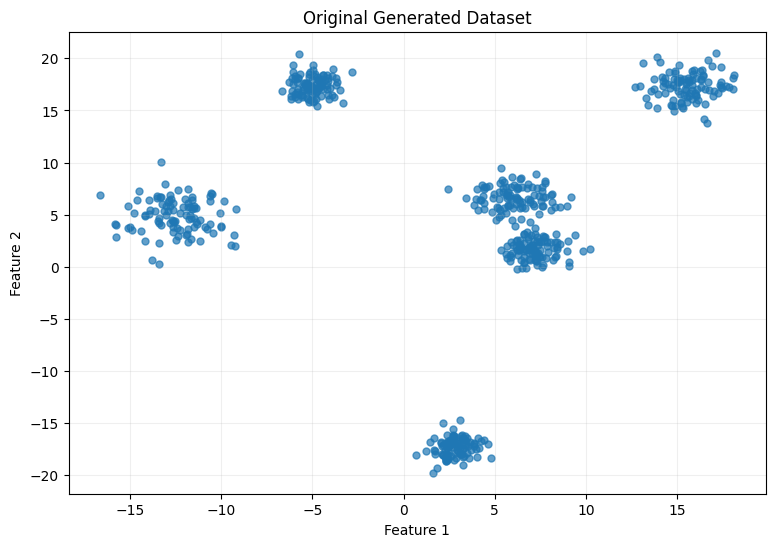

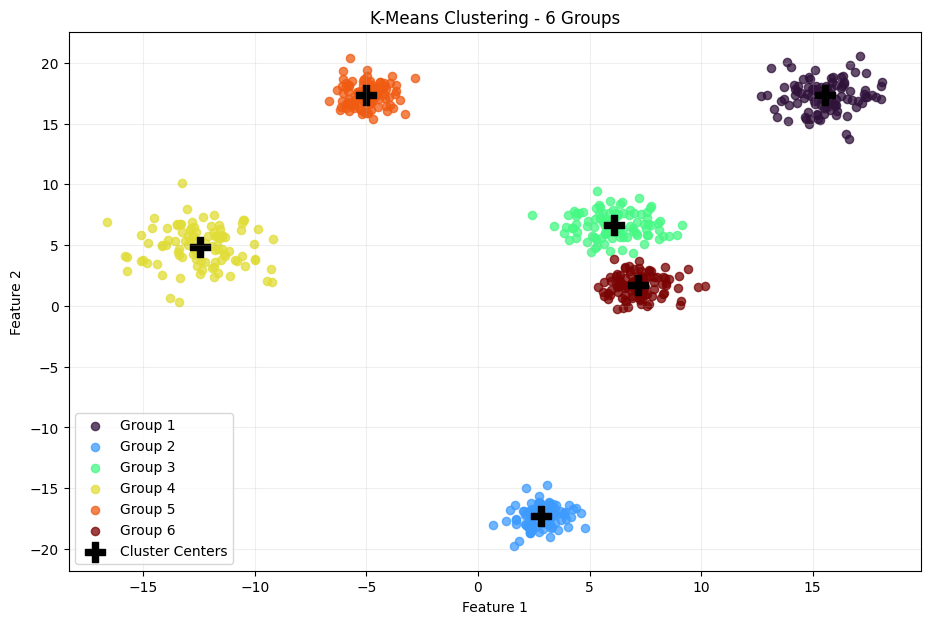

Dataset Size: 600
Features: 2
Clusters: 6
Iterations: 3
Inertia: 1515.74
Silhouette Score: 0.7911

Cluster Distribution:
Cluster 1: 100 points
Cluster 2: 100 points
Cluster 3: 99 points
Cluster 4: 100 points
Cluster 5: 100 points
Cluster 6: 101 points


In [14]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

data, _ = make_blobs(
    n_samples=600,
    centers=6,
    n_features=2,
    cluster_std=[0.8, 1.2, 1.0, 1.5, 0.9, 1.3],
    center_box=(-20, 20),
    random_state=75
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    data[:, 0],
    data[:, 1],
    s=25,
    alpha=0.7
)

ax.set_title("Original Generated Dataset")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.grid(alpha=0.2)

plt.show()

model = KMeans(
    n_clusters=6,
    init="k-means++",
    n_init=25,
    max_iter=400,
    tol=0.0001,
    random_state=75
)

predicted_clusters = model.fit_predict(data)

cluster_centers = model.cluster_centers_

fig, ax = plt.subplots(figsize=(11, 7))

colors = plt.cm.turbo(np.linspace(0, 1, 6))

for cluster_id, color in enumerate(colors):

    selected_points = data[predicted_clusters == cluster_id]

    ax.scatter(
        selected_points[:, 0],
        selected_points[:, 1],
        color=color,
        s=35,
        alpha=0.75,
        label=f"Group {cluster_id + 1}"
    )

ax.scatter(
    cluster_centers[:, 0],
    cluster_centers[:, 1],
    marker="P",
    color="black",
    s=220,
    label="Cluster Centers"
)

ax.set_title("K-Means Clustering - 6 Groups")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

score = silhouette_score(data, predicted_clusters)

print("Dataset Size:", data.shape[0])
print("Features:", data.shape[1])
print("Clusters:", model.n_clusters)
print("Iterations:", model.n_iter_)
print("Inertia:", round(model.inertia_, 2))
print("Silhouette Score:", round(score, 4))

print("\nCluster Distribution:")

unique_labels, counts = np.unique(
    predicted_clusters,
    return_counts=True
)

for label, count in zip(unique_labels, counts):
    print(f"Cluster {label + 1}: {count} points")
